# CWE classification: flat ranking and graph traversal

This notebook compares four models (a lexical baseline, a vector-database lookup, and two Jev-compatible LLM selectors) under three methods: picking from the full catalog at once (flat), or using the CWE hierarchy to narrow candidates (greedy or beam traversal). Every model/method system is evaluated on the same held-out examples. Treat this as an experimental workflow: the lexical scorer is a transparent reference baseline, and the notebook does not establish that any system is generally superior.

Prepare a versioned benchmark with `uv run python -m experiment.fetch_sources` from the repository root. It downloads a pinned snapshot of GitHub-reviewed advisories (GHSA) and writes the benchmark and its report under `experiment/data/prepared/`. Gold labels are the CWE IDs GitHub curators assign to reviewed advisories: curated and consistently sourced, but not independently adjudicated, and limited to open-source package advisories. Explicit CWE mentions are removed from the input text.

Dataset questions (label distribution, unsupported CWEs, split balance) live in `dataset_analysis.ipynb`; review it before interpreting metrics. Use `dev` for choices about thresholds, margins, beam width, and scoring; reserve `test` for the frozen comparison.

In [1]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd

from classification import CWEGraph, normalize_label
from experiment import default_config
from experiment.runner import run_experiment

pd.set_option("display.precision", 3)

## Setup

Every model runs under every method on the held-out `test` split (fixed seed, 500 sampled examples). Run from the repository root with `uv run --extra notebook jupyter lab`.

| Model | Kind | How it ranks CWEs |
|---|---|---|
| `lexical` | scorer | Token overlap with CWE names/descriptions (reference baseline) |
| `vector` | scorer | Cosine similarity against the committed Chroma index (`chroma/`) |
| `jev` | selector | Jev picks among offered CWEs; traversal offers an explicit STOP option |
| `jev-parent` | selector | Same, but traversal offers the current CWE itself instead of STOP |

The Jev models need `TYPESAFE_API_KEY`, read from the shell or from `experiment/.env` (gitignored; optionally also `TYPESAFE_BASE_URL` and an immutable `TYPESAFE_DEFAULT_MODEL` such as `jev-1.13.0`). They send vulnerability descriptions and CWE definitions to that service and make several requests per example, so check usage in the cost table below. Jev accepts at most 255 options per question, so `jev/flat` over the whole catalog is skipped. Never put credentials in notebook cells or outputs.

Methods:

- **Flat** considers the full eligible CWE catalog at once and returns its highest-ranked labels.
- **Greedy** walks the selected `ChildOf` hierarchy from the roots, keeping one route at a time.
- **Beam** keeps up to `beam_width` routes, allowing more than one branch to survive each step.

Models come in two kinds:

- **Scorers** (`lexical`, `vector`) give each CWE an independent score. Thresholds filter candidates; the default `specificity` stopping policy avoids stopping at broad categories and allows margin-based stopping at Base/Variant categories. Scores must be comparable across candidate sets and branches for these rules to be meaningful.
- **Selectors** (Jev) choose among the offered options in one question. Flat offers every CWE (skipped when that exceeds the selector's option limit); greedy and beam offer a node's children plus a way to stop at that node: an explicit **STOP** option (`jev`) or the node's own CWE as an option (`jev-parent`). Beam ranks paths by the product of their choice probabilities, so scores never need to be compared across separate questions.

The hierarchy is a directed acyclic graph, so nodes may have multiple parents or be disconnected; see the classifier implementation for traversal details.

**Growing the sample later.** Examples are drawn from one seeded shuffle of the split, so the first 500 are always part of a later 2,000 run. Predictions already saved in `config["output"]` are reused and only the new examples are sent to the models, as long as the benchmark file and the prediction settings (split, view, seed, beam width, top-k, threshold, margin, stop policy) are unchanged. Pin `TYPESAFE_DEFAULT_MODEL` so new Jev answers come from the same model version; the run stops if the version changed. Running a *smaller* sample into the same folder overwrites the larger files.

In [2]:
import os

env_file = Path.cwd() / "experiment" / ".env"
if env_file.is_file():
    for line in env_file.read_text(encoding="utf-8").splitlines():
        name, separator, value = line.strip().partition("=")
        if separator and name and not name.startswith("#"):
            os.environ.setdefault(name.strip(), value.strip().strip("\"'"))

config = default_config(Path.cwd())
config

{'catalog': 'data/all.csv',
 'benchmark': 'experiment/data/prepared/benchmark.jsonl',
 'output': 'experiment/results',
 'view': '1000',
 'split': 'test',
 'models': {'lexical': 'lexical',
  'vector': 'vector',
  'jev': 'experiment.jev_selector:create_selector',
  'jev-parent': 'experiment.jev_selector:create_parent_selector'},
 'methods': ['flat', 'greedy', 'beam'],
 'max_examples': 500,
 'beam_width': 3,
 'top_k': 5,
 'threshold': 0.0,
 'margin': 0.0,
 'stop_policy': 'specificity',
 'seed': 0}

## Run the matched comparison

The runner uses one seeded selection for every system, then saves per-example predictions and aggregate metrics. Re-running with the same benchmark bytes and configuration reproduces the selected examples and non-model sampling; remote model outputs may still vary. The output lists the evaluated sample (population size, sample size, benchmark hash) and any skipped systems.

In [3]:
summary = run_experiment(config)
prediction_records = {
    system: [
        json.loads(line)
        for line in (Path(config["output"]) / f"{system.replace('/', '-')}.jsonl")
        .read_text(encoding="utf-8")
        .splitlines()
        if line.strip()
    ]
    for system in summary["systems"]
}
display(pd.Series(summary["examples"], name="sample").to_frame())
display(pd.Series(summary["reused"], name="reused predictions").to_frame())
pd.Series(summary["skipped"], name="skipped (reason)", dtype="object").to_frame()

,sample
split,test
population,27055
evaluated,500
sha256,9fc6c96408035aadfccfd39cbca7a05e685f7e0c0294d8...


,reused predictions
lexical/flat,0
lexical/greedy,0
lexical/beam,0
vector/flat,0
vector/greedy,0
vector/beam,0
jev/greedy,0
jev/beam,0
jev-parent/greedy,0
jev-parent/beam,0


,skipped (reason)
jev/flat,938 catalog CWEs exceed the 255-option limit
jev-parent/flat,938 catalog CWEs exceed the 255-option limit


### Helpers

Shared hierarchy helpers used by the analysis below.

In [4]:
graph = CWEGraph(config["catalog"], config["view"])
_chain_memo = {}


def split_system(system):
    model, method = system.split("/")
    return {"model": model, "method": method}


def cwe_name(label):
    return label if label == "STOP" else f"CWE-{label} {graph.labels[label]['Name']}"


def chains(label):
    """Every root-to-label path in the hierarchy."""
    if label not in _chain_memo:
        parents = sorted(graph.parents[label])
        _chain_memo[label] = (
            [[label]] if not parents
            else [chain + [label] for parent in parents for chain in chains(parent)]
        )
    return _chain_memo[label]


def ancestors(label):
    """The label and every CWE above it."""
    return {node for chain in chains(label) for node in chain}


def gold_labels(record):
    return {normalize_label(label) for label in record["labels"]} & graph.labels.keys()


def route_nodes(gold):
    """Gold CWEs and all their ancestors."""
    return set().union(*(ancestors(label) for label in gold))


def top1(record):
    return [normalize_label(label) for label in record["predictions"][:1]]

## Results

**Top-1 accuracy** is the headline number: an example counts as correct when the system's first prediction is one of the curator's CWEs. The **95% interval** shows how much that accuracy could move just from which examples happened to be sampled; when two systems' intervals overlap heavily, the sample cannot tell them apart. Intervals cover sampling noise only, not label noise.

The other columns:

- **recall@k**: a gold CWE appears anywhere in the first *k* predictions.
- **abstention**: the system returned nothing.
- **hier. P / R / F1**: partial credit for near misses. Each label is expanded to itself plus every CWE above it; precision is how much of the predicted chain is shared with the gold chain, recall how much of the gold chain was covered.
- **macro F1**: top-1 F1 averaged over every gold CWE in the sample, so rare CWEs count as much as CWE-79.

In [5]:
rows = []
for system, records in prediction_records.items():
    metrics = summary["systems"][system]
    overlap = predicted = expected = 0
    true_positive, predicted_count, gold_count = Counter(), Counter(), Counter()
    for record in records:
        gold, top = gold_labels(record), [label for label in top1(record) if label in graph.labels]
        gold_set = route_nodes(gold)
        predicted_set = ancestors(top[0]) if top else set()
        overlap += len(gold_set & predicted_set)
        predicted += len(predicted_set)
        expected += len(gold_set)
        gold_count.update(gold)
        predicted_count.update(top)
        true_positive.update(set(top) & gold)
    h_precision = overlap / predicted if predicted else 0.0
    h_recall = overlap / expected if expected else 0.0
    f1 = [2 * true_positive[label] / (predicted_count[label] + gold_count[label])
          for label in gold_count]
    rows.append({
        **split_system(system),
        "accuracy": metrics["accuracy"],
        "95% low": metrics["accuracy_95ci"][0],
        "95% high": metrics["accuracy_95ci"][1],
        **{f"recall@{k}": value for k, value in metrics["top_k_recall"].items() if k > 1},
        "abstention": metrics["abstention_rate"],
        "hier. P": h_precision,
        "hier. R": h_recall,
        "hier. F1": (2 * h_precision * h_recall / (h_precision + h_recall)
                     if h_precision + h_recall else 0.0),
        "macro F1": sum(f1) / len(f1) if f1 else 0.0,
    })
results_table = pd.DataFrame(rows).set_index(["model", "method"]).sort_values(
    "accuracy", ascending=False
)
results_table.style.format(precision=3).background_gradient(
    subset=["accuracy", "hier. F1", "macro F1"], cmap="Greens"
)

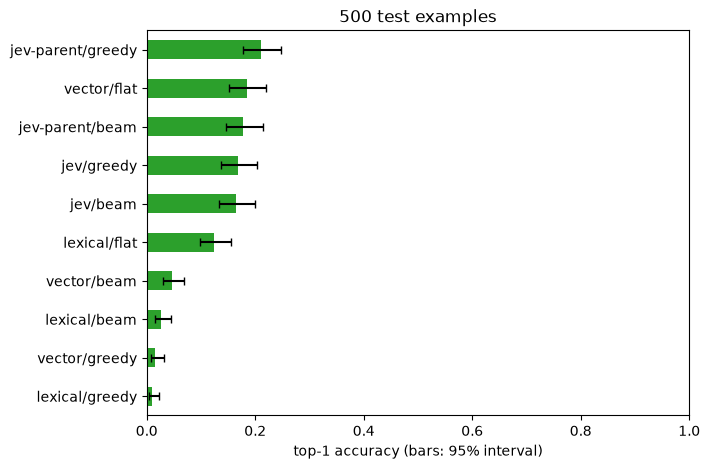

In [6]:
ordered = results_table.sort_values("accuracy")
labels = [f"{model}/{method}" for model, method in ordered.index]
ax = pd.Series(ordered["accuracy"].values, index=labels).plot.barh(
    xerr=[ordered["accuracy"] - ordered["95% low"], ordered["95% high"] - ordered["accuracy"]],
    capsize=3, figsize=(7, 0.4 * len(labels) + 1), xlim=(0, 1), color="tab:green",
)
ax.set(xlabel="top-1 accuracy (bars: 95% interval)",
       title=f"{summary['examples']['evaluated']} {config['split']} examples");

### Per-CWE top-1 results

Precision, recall, and F1 for the most frequent gold CWEs in the sample, per system. Use this to see which weakness families each system handles well.

In [7]:
label_rows = []
for system, records in prediction_records.items():
    for record in records:
        gold = gold_labels(record)
        top = top1(record)
        for label in gold | set(top):
            label_rows.append({
                "system": system, "cwe": label,
                "tp": int(label in gold and label in top),
                "gold": int(label in gold), "predicted": int(label in top),
            })
per_label = pd.DataFrame(label_rows).groupby(["cwe", "system"]).sum()
per_label["precision"] = per_label["tp"] / per_label["predicted"].where(per_label["predicted"] > 0)
per_label["recall"] = per_label["tp"] / per_label["gold"].where(per_label["gold"] > 0)
per_label["F1"] = 2 * per_label["tp"] / (per_label["gold"] + per_label["predicted"])
frequent = Counter(label for record in next(iter(prediction_records.values()))
                   for label in gold_labels(record))
top_labels = [label for label, _ in frequent.most_common(15)]
per_cwe_f1 = per_label["F1"].unstack("system").reindex(top_labels)
per_cwe_f1.index = [f"{cwe_name(label)} (n={frequent[label]})" for label in per_cwe_f1.index]
per_cwe_f1.style.format(precision=2, na_rep="—").background_gradient(axis=None, cmap="Greens")

system,jev-parent/beam,jev-parent/greedy,jev/beam,jev/greedy,lexical/beam,lexical/flat,lexical/greedy,vector/beam,vector/flat,vector/greedy
CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting') (n=67),0.67,0.70,0.49,0.49,0.13,0.44,0.08,0.03,0.42,0.00
CWE-22 Improper Limitation of a Pathname to a Restricted Directory ('Path Traversal') (n=33),0.00,0.00,0.00,0.00,0.06,0.06,0.00,0.06,0.11,0.00
CWE-400 Uncontrolled Resource Consumption (n=23),0.07,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CWE-918 Server-Side Request Forgery (SSRF) (n=21),0.00,0.00,0.00,0.00,0.00,0.50,0.08,0.00,0.50,0.00
CWE-862 Missing Authorization (n=20),0.34,0.47,0.37,0.48,0.00,0.09,0.00,0.00,0.00,0.00
CWE-20 Improper Input Validation (n=19),0.13,0.16,0.17,0.21,0.00,0.00,0.00,0.00,0.00,0.00
CWE-200 Exposure of Sensitive Information to an Unauthorized Actor (n=18),0.00,0.00,0.00,0.00,0.00,0.10,0.00,0.00,0.00,0.00
CWE-770 Allocation of Resources Without Limits or Throttling (n=16),0.00,0.11,0.11,0.00,0.00,0.00,0.00,0.21,0.00,0.00
CWE-863 Incorrect Authorization (n=14),0.17,0.24,0.21,0.23,0.00,0.00,0.00,0.00,0.00,0.00
CWE-352 Cross-Site Request Forgery (CSRF) (n=12),0.29,0.29,0.40,0.40,0.00,0.40,0.00,0.00,0.15,0.00


### Cost and latency per example

Means over evaluated examples. Token counts are blank for local models, which do not report usage.

In [8]:
cost_table = pd.DataFrame([
    {
        **split_system(system),
        "calls": record["calls"],
        "input tokens": record.get("input_tokens"),
        "output tokens": record.get("output_tokens"),
        "latency (s)": record["latency_seconds"],
    }
    for system, records in prediction_records.items()
    for record in records
]).groupby(["model", "method"]).mean()
cost_table.style.format(precision=2, na_rep="—")

## Where does each system fail?

Each top prediction is traced along the `ChildOf` hierarchy and compared with the route(s) from a root to a gold CWE. A node is *on route* if it is a gold CWE or one of its ancestors. Greedy and beam use their recorded path; flat uses the root-to-prediction chain that stays on route longest.

- **correct**: ended on a gold CWE.
- **stopped too early**: stayed on route but stopped at an ancestor of the gold CWE.
- **went past gold**: reached the gold CWE but kept descending.
- **wrong root** / **wrong branch**: left the route at step 1 / a later step.
- **abstained**, **gold not in catalog**: no prediction, or the gold label is outside the selected view.

Use these on `dev` to decide what to change (e.g. stopping vs. routing); don't retune on `test`.

In [9]:
OUTCOMES = (
    "correct", "stopped too early", "went past gold", "wrong root",
    "wrong branch", "abstained", "gold not in catalog",
)


def diagnose(record):
    """Find the first decision where the top prediction left every gold route.

    Greedy/beam use the recorded path; flat uses the root-to-prediction chain
    that stays on route longest. step is 1-based (1 = choosing a root).
    """
    gold = gold_labels(record)
    predictions = [normalize_label(label) for label in record["predictions"]]
    result = {"outcome": None, "step": None, "chose": None, "expected": [], "path": []}
    if not gold:
        return {**result, "outcome": "gold not in catalog"}
    if record.get("abstained") or not predictions:
        return {**result, "outcome": "abstained"}
    on_route = route_nodes(gold)

    def on_route_prefix(path):
        return next((i for i, node in enumerate(path) if node not in on_route), len(path))

    path = (
        [normalize_label(node) for node in record["paths"][0]] if record.get("paths")
        else max(chains(predictions[0]), key=on_route_prefix)
    )
    result["path"] = path
    if path[-1] in gold:
        return {**result, "outcome": "correct"}
    passed = next((i for i, node in enumerate(path[:-1]) if node in gold), None)
    if passed is not None:
        return {**result, "outcome": "went past gold", "step": passed + 2,
                "chose": path[passed + 1], "expected": ["STOP"]}
    index = on_route_prefix(path)
    if index == len(path):
        return {**result, "outcome": "stopped too early", "step": index + 1, "chose": "STOP",
                "expected": sorted(graph.children[path[-1]] & on_route)}
    if index == 0:
        return {**result, "outcome": "wrong root", "step": 1, "chose": path[0],
                "expected": sorted(set(graph.roots) & on_route)}
    return {**result, "outcome": "wrong branch", "step": index + 1, "chose": path[index],
            "expected": sorted(graph.children[path[index - 1]] & on_route)}


diagnoses = pd.DataFrame([
    {**split_system(system), "id": record["id"], **diagnose(record),
     "gold": [normalize_label(label) for label in record["labels"]]}
    for system, records in prediction_records.items()
    for record in records
])
outcome_table = pd.crosstab(
    [diagnoses["model"], diagnoses["method"]], diagnoses["outcome"], normalize="index"
).reindex(columns=[outcome for outcome in OUTCOMES if outcome in set(diagnoses["outcome"])])
outcome_table.style.format("{:.0%}").background_gradient(axis=None, cmap="Reds")

### Which step goes wrong?

Share of each system's examples that first go wrong at each step (step 1 = choosing a root). Correct and abstained examples are excluded.

In [10]:
failures = diagnoses[diagnoses["step"].notna()].astype({"step": int})
step_table = pd.crosstab(
    [failures["model"], failures["method"]],
    [failures["outcome"], failures["step"]],
).div(diagnoses.groupby(["model", "method"]).size(), axis=0).fillna(0)
step_table.style.format("{:.0%}")

### Example drill-down

Failed examples with CWE names: the route taken, the step that went wrong, what was chosen, and the on-route options that should have been chosen. Filter by `model`, `method`, or `outcome` as needed.

In [11]:
drilldown = failures.assign(
    gold=failures["gold"].map(lambda labels: "; ".join(
        cwe_name(label) if label in graph.labels else f"CWE-{label}" for label in labels
    )),
    path=failures["path"].map(lambda path: " → ".join(map(cwe_name, path))),
    chose=failures["chose"].map(cwe_name),
    expected=failures["expected"].map(lambda labels: "; ".join(map(cwe_name, labels))),
)[["id", "model", "method", "gold", "outcome", "step", "path", "chose", "expected"]]
with pd.option_context("display.max_colwidth", None):
    display(drilldown.sort_values(["id", "model", "method"]).head(30))

,id,model,method,gold,outcome,step,path,chose,expected
1000,GHSA-22JM-P2VV-J2HC,lexical,beam,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong root,1,CWE-664 Improper Control of a Resource Through its Lifetime → CWE-610 Externally Controlled Reference to a Resource in Another Sphere → CWE-601 URL Redirection to Untrusted Site ('Open Redirect'),CWE-664 Improper Control of a Resource Through its Lifetime,CWE-707 Improper Neutralization
0,GHSA-22JM-P2VV-J2HC,lexical,flat,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong root,1,CWE-697 Incorrect Comparison → CWE-1023 Incomplete Comparison with Missing Factors → CWE-184 Incomplete List of Disallowed Inputs → CWE-692 Incomplete Denylist to Cross-Site Scripting,CWE-697 Incorrect Comparison,CWE-707 Improper Neutralization
500,GHSA-22JM-P2VV-J2HC,lexical,greedy,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong root,1,CWE-697 Incorrect Comparison → CWE-185 Incorrect Regular Expression → CWE-186 Overly Restrictive Regular Expression,CWE-697 Incorrect Comparison,CWE-707 Improper Neutralization
2500,GHSA-22JM-P2VV-J2HC,vector,beam,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong root,1,CWE-693 Protection Mechanism Failure → CWE-602 Client-Side Enforcement of Server-Side Security → CWE-603 Use of Client-Side Authentication,CWE-693 Protection Mechanism Failure,CWE-707 Improper Neutralization
1500,GHSA-22JM-P2VV-J2HC,vector,flat,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong root,1,CWE-697 Incorrect Comparison → CWE-1023 Incomplete Comparison with Missing Factors → CWE-184 Incomplete List of Disallowed Inputs → CWE-692 Incomplete Denylist to Cross-Site Scripting,CWE-697 Incorrect Comparison,CWE-707 Improper Neutralization
2000,GHSA-22JM-P2VV-J2HC,vector,greedy,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),wrong branch,2,CWE-707 Improper Neutralization → CWE-116 Improper Encoding or Escaping of Output → CWE-644 Improper Neutralization of HTTP Headers for Scripting Syntax,CWE-116 Improper Encoding or Escaping of Output,CWE-74 Improper Neutralization of Special Elements in Output Used by a Downstream Component ('Injection')
3501,GHSA-22XM-W7R2-834Q,jev,beam,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),went past gold,4,CWE-707 Improper Neutralization → CWE-74 Improper Neutralization of Special Elements in Output Used by a Downstream Component ('Injection') → CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting') → CWE-80 Improper Neutralization of Script-Related HTML Tags in a Web Page (Basic XSS),CWE-80 Improper Neutralization of Script-Related HTML Tags in a Web Page (Basic XSS),STOP
3001,GHSA-22XM-W7R2-834Q,jev,greedy,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),went past gold,4,CWE-707 Improper Neutralization → CWE-74 Improper Neutralization of Special Elements in Output Used by a Downstream Component ('Injection') → CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting') → CWE-80 Improper Neutralization of Script-Related HTML Tags in a Web Page (Basic XSS),CWE-80 Improper Neutralization of Script-Related HTML Tags in a Web Page (Basic XSS),STOP
4501,GHSA-22XM-W7R2-834Q,jev-parent,beam,CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting'),went past gold,4,CWE-707 Improper Neutralization → CWE-74 Improper Neutralization of Special Elements in Output Used by a Downstream Component ('Injection') → CWE-79 Improper Neutralization of Input During Web Page Generation ('Cross-site Scripting') → CWE-80 Improper Neutralization of Script-Related HTML Tags in a Web Page (Basic XSS),CWE-80 Improper Neutralization of Scr

## Jev decisions

Jev systems save every question they were asked (`steps`: the node they were at and the probability of each offered option), so individual decisions can be analyzed without re-querying the model. Scorers save only their ranked predictions and are not included here.

### Step accuracy and calibration

A question asked *from an on-route node* has at least one correct answer: an on-route child, or `STOP` when the current node is a gold CWE (root questions count every on-route root). Questions asked after the route was already lost have no correct answer and are excluded. The first table shows decision accuracy and mean confidence by depth (1 = choosing a root). The calibration plot bins decisions by the probability of the chosen option; a well-calibrated model sits on the diagonal, and ECE is the average gap.

In [12]:
selector_systems = {
    system: records for system, records in prediction_records.items()
    if any(record.get("steps") for record in records)
}
decisions = []
for system, records in selector_systems.items():
    flat_method = split_system(system)["method"] == "flat"
    for record in records:
        gold = gold_labels(record)
        on_route = route_nodes(gold)
        depth_of = {None: 1}
        for path in record["paths"]:
            for depth, node in enumerate(path, start=2):
                depth_of.setdefault(node, depth)
        for step in record["steps"]:
            current, probabilities = step["current"], step["probabilities"]
            if current is not None and current not in on_route:
                continue
            if flat_method:
                correct = set(probabilities) & gold
            else:
                correct = {option for option in probabilities
                           if option in on_route or (option == "STOP" and current in gold)}
            if not correct:
                continue
            chose, confidence = max(probabilities.items(), key=lambda item: (item[1], item[0]))
            decisions.append({
                **split_system(system), "id": record["id"],
                "depth": depth_of.get(current), "options": len(probabilities),
                "chose": chose, "confidence": confidence,
                "correct": chose in correct,
                "p(correct)": sum(probabilities[option] for option in correct),
            })
decisions = pd.DataFrame(decisions, columns=[
    "model", "method", "id", "depth", "options", "chose", "confidence", "correct", "p(correct)",
])
if decisions.empty:
    print("No Jev steps recorded.")
else:
    display(decisions.groupby(["model", "method", "depth"]).agg(
        decisions=("correct", "size"), accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean"), mean_p_correct=("p(correct)", "mean"),
    ).style.format(precision=2))

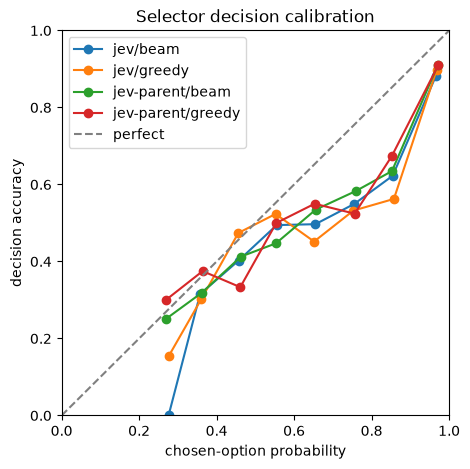

In [13]:
if not decisions.empty:
    bins = pd.cut(decisions["confidence"], bins=[i / 10 for i in range(11)], include_lowest=True)
    calibration = decisions.groupby(["model", "method", bins], observed=True).agg(
        decisions=("correct", "size"), accuracy=("correct", "mean"),
        confidence=("confidence", "mean"),
    )
    gap = (calibration["accuracy"] - calibration["confidence"]).abs() * calibration["decisions"]
    ece = (gap.groupby(level=["model", "method"]).sum()
           / calibration["decisions"].groupby(level=["model", "method"]).sum())
    display(ece.rename("ECE").to_frame().style.format(precision=3))
    ax = None
    for (model, method), group in calibration.groupby(level=["model", "method"]):
        ax = group.plot.line(x="confidence", y="accuracy", marker="o", ax=ax,
                             label=f"{model}/{method}", figsize=(5, 5))
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="chosen-option probability",
           ylabel="decision accuracy", title="Selector decision calibration")
    ax.legend()

### Accuracy vs. coverage

A selector's confidence in its top prediction is the probability of its path: the product of the chosen option at every step, times P(STOP) where it stopped before a leaf. Keeping only the most confident examples should raise accuracy; a flat curve means the confidence is uninformative.

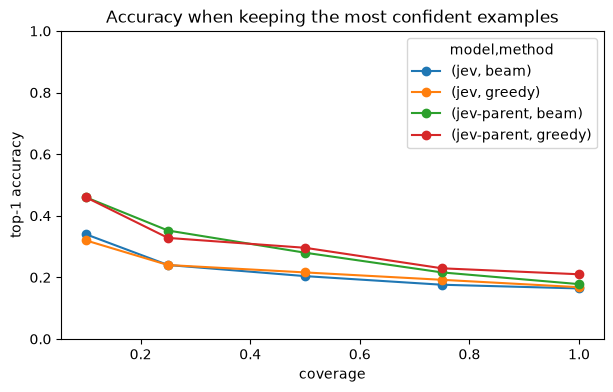

In [14]:
def path_probability(record):
    if not record.get("paths"):
        return None
    by_current = {}
    for step in record["steps"]:
        by_current.setdefault(step["current"], step["probabilities"])
    path, probability, current = record["paths"][0], 1.0, None
    for node in path:
        if current not in by_current or node not in by_current[current]:
            return None
        probability *= by_current[current][node]
        current = node
    if current in by_current and "STOP" in by_current[current]:
        probability *= by_current[current]["STOP"]
    return probability


coverage_rows = []
for system, records in selector_systems.items():
    scored = sorted(
        ((path_probability(record),
          bool(gold_labels(record) & {normalize_label(label) for label in record["predictions"][:1]}))
         for record in records),
        key=lambda item: -(item[0] or 0),
    )
    for fraction in (0.1, 0.25, 0.5, 0.75, 1.0):
        kept = scored[:max(1, round(fraction * len(scored)))]
        coverage_rows.append({
            **split_system(system), "coverage": fraction,
            "accuracy": sum(correct for _, correct in kept) / len(kept),
            "min confidence": kept[-1][0],
        })
coverage = pd.DataFrame(coverage_rows, columns=["model", "method", "coverage", "accuracy", "min confidence"])
if coverage.empty:
    print("No selector systems to analyze.")
else:
    curve = coverage.pivot_table(index="coverage", columns=["model", "method"], values="accuracy")
    curve.plot(marker="o", figsize=(7, 4), ylim=(0, 1), ylabel="top-1 accuracy",
               title="Accuracy when keeping the most confident examples")
    display(curve.style.format(precision=3))

## Reproducibility checklist

- Prediction JSONL files keep each selector's per-step option probabilities (`steps`), so new decision-level analyses can be run without re-querying the model.
- Preserve the dataset report (with the advisory snapshot revision), benchmark file, and its recorded SHA-256 alongside `metrics.json` and prediction JSONL files.
- Record the repository revision, Python/dependency lockfile, split, models (and remote model versions), seed, and all settings when reporting results.
- Keep test-set decisions frozen. Curator labels are imperfect, and this experiment is exploratory unless evaluated on independently reviewed labels.
- Review saved notebook outputs before sharing; do not publish private vulnerability descriptions, credentials, or sensitive local paths.